# Prototype 20 — Jev vs. Gemini on Outfit-Suggest Ranking

**Goal:** Answer the Phase 0 gate from `notes/ai-generated/jev-integration-plan.md`: is Jev's decision quality on outfit ranking good enough to justify a safety-net rollout on `src/ai/suggest.ts`?

**Decision criterion (per plan):**
- Agreement > 75% (Jev top-1 ∈ Gemini top-3)
- Median calibrated confidence > 0.65
- Latency < 2× Gemini
- Cost per call cheaper than Gemini

**Approach:**
- Load real closet items + outfits from `~/.closet/closet.db` (read-only) — reuse the loader pattern from notebook 19.
- No prior notebook loads outfits; the outfit loader here is new.
- Weather + occasion fixtures: 10 hand-authored scenarios (extends notebook 09's 3).
- **Gemini baseline:** reproduces the exact prompt from `src/ai/suggest.ts` lines 93-107. No embedding pre-filter — fixture closets are small enough that the full closet is the shortlist.
- **Jev experimental:** routed via OpenRouter's **native decisions endpoint** `POST https://openrouter.ai/api/alpha/decisions`. This preserves TypeSafe's full response shape: `answers[qid].{choice, confidence, probabilities}` — real RLCD-calibrated confidence, not self-reported. Discovered during smoke testing; the plan doc's "OpenRouter is lossy" assumption was stale as of Sep 2026.

**Tradeoffs acknowledged:**
1. **We're skipping the embedding pre-filter.** In production, `topKText()` narrows the closet to 12 items before ranking. Fixture closets here are ≤ 30 items — behaviour still comparable, but cost/latency numbers are for the ranking step only.
2. **Gemini baseline via `lib/providers.py`, not by importing `suggest.ts`.** Same prompt, same model. Cheaper than setting up a `tsx` subprocess.
3. **Fixture set is small (10 scenarios).** Enough for a Phase 0 signal; not enough for a statistical claim. If Phase 0 passes, Phase 1 should expand to ~100 scenarios with human-labelled ground truth.

**Sources referenced:**
- Native SDK research: `notes/ai-generated/jev-integration-plan.md`
- `src/ai/suggest.ts` for the prompt template + return shape (`OutfitSuggestion[]`)
- Notebook 19 for the closet loader pattern
- Notebook 09 for weather/occasion fixtures scaffolding


## 1. Setup — imports, env, paths


In [36]:
from __future__ import annotations

import json
import os
import sqlite3
import statistics
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

REPO_ROOT = Path.cwd().parent.parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Load .env if present (matches other notebooks' convention)
env_path = REPO_ROOT / ".env"
if env_path.exists():
    for line in env_path.read_text().splitlines():
        line = line.strip()
        if not line or line.startswith("#") or "=" not in line:
            continue
        k, v = line.split("=", 1)
        os.environ.setdefault(k.strip(), v.strip().strip('"').strip("'"))

from prototypes.lib.providers import all_providers, print_availability

CLOSET_DATA_DIR = Path(os.environ.get("CLOSET_DATA_DIR", str(Path.home() / ".closet")))
CLOSET_DB = CLOSET_DATA_DIR / "closet.db"
OUT_DIR = REPO_ROOT / "prototypes" / "outputs" / "20"
OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR = REPO_ROOT / "prototypes" / "cache"
CACHE_DIR.mkdir(exist_ok=True)

print(f"CLOSET_DB:      {CLOSET_DB}  exists={CLOSET_DB.exists()}")
print(f"OUT_DIR:        {OUT_DIR}")
print(f"OPENROUTER_API_KEY set: {bool(os.environ.get('OPENROUTER_API_KEY'))}")
print(f"GEMINI_API_KEY   set:   {bool(os.environ.get('GEMINI_API_KEY'))}")

providers = all_providers()
print_availability(providers)


CLOSET_DB:      .closet/closet.db  exists=True
OUT_DIR:        prototypes/outputs/20
OPENROUTER_API_KEY set: True
GEMINI_API_KEY   set:   True
  gemini       ✓ ready
  openrouter   ✓ ready
  fal          ✗ key missing


## 2. Jev client — hit OpenRouter's `/api/alpha/decisions` endpoint

`lib/providers.py`'s OpenAI-compat wrapper can't reach this endpoint (it's not `/chat/completions`), so we POST directly with `urllib.request`. No new dependency.

Endpoint: `POST https://openrouter.ai/api/alpha/decisions`. Auth: standard OpenRouter bearer token. Response body has native TypeSafe shape (`answers[qid].{choice, confidence, probabilities}`) plus `usage.cost` in real USD.

In [38]:
import urllib.request
import urllib.error

JEV_MODEL = "typesafe/jev-1.13"
DECISIONS_URL = "https://openrouter.ai/api/alpha/decisions"


def call_jev_decisions(state, questions: dict, *, timeout_s: int = 30) -> dict:
    """POST to OpenRouter's decisions endpoint. Returns a dict with:
      {ok: bool, latency_s, model, answers, usage, error?}"""
    api_key = os.environ.get("OPENROUTER_API_KEY", "")
    if not api_key:
        return {"ok": False, "error": "OPENROUTER_API_KEY not set"}
    body = json.dumps({"model": JEV_MODEL, "state": state, "questions": questions}).encode()
    req = urllib.request.Request(
        DECISIONS_URL,
        data=body,
        method="POST",
        headers={"Authorization": f"Bearer {api_key}", "Content-Type": "application/json"},
    )
    t0 = time.perf_counter()
    try:
        with urllib.request.urlopen(req, timeout=timeout_s) as resp:
            payload = json.loads(resp.read())
        return {
            "ok": True,
            "latency_s": time.perf_counter() - t0,
            "model": payload.get("model"),
            "answers": payload.get("answers") or {},
            "usage": payload.get("usage") or {},
            "id": payload.get("id"),
            "provider": payload.get("provider"),
        }
    except urllib.error.HTTPError as e:
        return {"ok": False, "latency_s": time.perf_counter() - t0,
                "error": f"HTTP {e.code}: {e.read()[:300].decode(errors='replace')}"}
    except Exception as e:
        return {"ok": False, "latency_s": time.perf_counter() - t0,
                "error": f"{type(e).__name__}: {e}"}


# Sanity probe — one tiny call to verify the endpoint is live.
probe = call_jev_decisions(
    state="It is 5°C, rainy. I need to go to the office.",
    questions={
        "pick": {
            "type": "choice",
            "instructions": "Which is better for this weather?",
            "criteria": {"wool_coat": "wool coat", "linen_shirt": "linen shirt"},
        },
        "is_cold": {"type": "noul", "instructions": "Is the temperature below 15°C?"},
    },
)
print(json.dumps(probe, indent=2, default=str))


{
  "ok": true,
  "latency_s": 0.2625057499972172,
  "model": "typesafe/jev-1.13-20260917",
  "answers": {
    "pick": {
      "type": "choice",
      "choice": "wool_coat",
      "probabilities": {
        "wool_coat": 1,
        "linen_shirt": 0
      },
      "confidence": 1
    },
    "is_cold": {
      "type": "noul",
      "noul": 0.99
    }
  },
  "usage": {
    "input_tokens": 347,
    "output_tokens": 58,
    "cost": 1.4574e-05
  },
  "id": "gen-dec-1789942302-x9joX7PAG0xsPTm8Gy8x",
  "provider": "TypeSafe"
}


## 3. Data loaders — closet items + outfits

Items loader borrowed verbatim from notebook 19. Outfit loader is new — no prior notebook has read the `outfits` table.

Schema notes (from `src/db/schema.ts`):
- `items`: rows keyed by `id`, JSON-serialized `colors`, `season`, `occasion`, `tags`.
- `outfits`: rows keyed by `id`, `itemIds` is a JSON array of item IDs, `userId` scopes each row.
- Per Step 20 (`Multi-user discipline`), every query MUST filter by `user_id`. We use the current authenticated user by picking the *most active* user in the DB (highest item count) — good enough for a read-only prototype.

In [40]:
def pick_active_user(db_path: Path) -> str | None:
    if not db_path.exists():
        return None
    conn = sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)
    row = conn.execute(
        "SELECT user_id, COUNT(*) c FROM items GROUP BY user_id ORDER BY c DESC LIMIT 1"
    ).fetchone()
    conn.close()
    return row[0] if row else None


def fetch_closet_items(db_path: Path, user_id: str) -> list[dict]:
    conn = sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)
    conn.row_factory = sqlite3.Row
    rows = conn.execute(
        """
        SELECT id, category, subcategory, colors, brand, material, season,
               occasion, tags, ai_description, image_uri, wear_context
        FROM items
        WHERE user_id = ?
        ORDER BY id
        """,
        (user_id,),
    ).fetchall()
    conn.close()
    out = []
    for r in rows:
        d = dict(r)
        for jf in ("colors", "season", "occasion", "tags"):
            try:
                d[jf] = json.loads(d[jf]) if d[jf] else []
            except (json.JSONDecodeError, TypeError):
                d[jf] = []
        out.append(d)
    return out


def fetch_closet_outfits(db_path: Path, user_id: str) -> list[dict]:
    conn = sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)
    conn.row_factory = sqlite3.Row
    rows = conn.execute(
        """
        SELECT id, name, item_ids, occasion, season, notes
        FROM outfits
        WHERE user_id = ?
        ORDER BY id
        """,
        (user_id,),
    ).fetchall()
    conn.close()
    out = []
    for r in rows:
        d = dict(r)
        for jf in ("item_ids", "season"):
            try:
                d[jf] = json.loads(d[jf]) if d[jf] else []
            except (json.JSONDecodeError, TypeError):
                d[jf] = []
        out.append(d)
    return out


ACTIVE_USER = pick_active_user(CLOSET_DB)
print(f"Active user (most items): {ACTIVE_USER}")

items = fetch_closet_items(CLOSET_DB, ACTIVE_USER) if ACTIVE_USER else []
outfits = fetch_closet_outfits(CLOSET_DB, ACTIVE_USER) if ACTIVE_USER else []
items_by_id = {it["id"]: it for it in items}

print(f"Items:   {len(items)}")
print(f"Outfits: {len(outfits)}")
if items:
    print("Sample item:", {k: v for k, v in items[0].items() if k not in ("image_uri",)})
if outfits:
    print("Sample outfit:", outfits[0])


Active user (most items): self
Items:   41
Outfits: 32
Sample item: {'id': '1krQ-viC9hmmEdTcZcXyr', 'category': 'tops', 'subcategory': 'button-down shirt', 'colors': ['white', 'blue'], 'brand': None, 'material': 'cotton', 'season': ['spring'], 'occasion': [], 'tags': ['casual', 'classic', 'everyday', 'workwear'], 'ai_description': 'A white button-down shirt featuring thin blue vertical stripes and a chest pocket.', 'wear_context': None}
Sample outfit: {'id': '3mjI4uL_liCuGuJMvrxOH', 'name': 'The Eccentric Urbanite', 'item_ids': ['zIuSli27hXkKD5xuPB5P8', 'vZxhL9Ip6dbZWa3d9YWEq', 'fEp-SguHFKkujiGIfryCH', 'RJgk9n2C6fprIQBKFhch_', 'gDIZ4giDLRa7zhyGIg_zD'], 'occasion': 'casual', 'season': [], 'notes': None}


### If the closet is empty or has no outfits

The ranking task requires ≥ 2 outfits. If the query returned nothing:
- Run `npm run seed:dev` from the repo root to populate the `demo-user-seed` account with 2 sample outfits.
- Or manually save a few outfits via the PWA before re-running this notebook.

We proceed only if `len(outfits) >= 2`.

## 4. Serialize items + outfits for the ranking prompt

The suggest.ts prompt gives the model a text listing of the closet, not raw JSON. Reproduce that projection so token counts + rankings are comparable.

In [43]:
def item_text(it: dict) -> str:
    parts = [it.get("category", "?")]
    if it.get("subcategory"):
        parts.append(it["subcategory"])
    if it.get("colors"):
        parts.append("/".join(it["colors"][:3]))
    if it.get("material"):
        parts.append(it["material"])
    if it.get("brand"):
        parts.append(f"({it['brand']})")
    return f"[{it['id']}] " + " ".join(str(p) for p in parts if p)


def outfit_text(o: dict, by_id: dict[str, dict]) -> str:
    names = []
    for iid in o.get("item_ids", []):
        it = by_id.get(iid)
        names.append(f"{it['category']}:{it.get('subcategory') or '?'}" if it else iid)
    header = f"[{o['id']}] {o.get('name') or 'Unnamed'} — occasion={o.get('occasion') or '?'}"
    return f"{header} — items: {', '.join(names) if names else '(empty)'}"


def closet_snapshot(items: list[dict]) -> str:
    return "\n".join(item_text(it) for it in items)


def outfits_snapshot(outfits: list[dict], by_id: dict[str, dict]) -> str:
    return "\n".join(outfit_text(o, by_id) for o in outfits)


if items:
    print("── ITEMS (first 5) ──")
    print("\n".join(item_text(it) for it in items[:5]))
if outfits:
    print("\n── OUTFITS (first 3) ──")
    print("\n".join(outfit_text(o, items_by_id) for o in outfits[:3]))


── ITEMS (first 5) ──
[1krQ-viC9hmmEdTcZcXyr] tops button-down shirt white/blue cotton
[6Sx16WaWjN6HPrbUx1VDc] accessories sunglasses black
[7H7pNDj7pt13ahx7I3mqj] tops button-down shirt green/blue/white
[A0otrtdLR8UKIQ9xdZocm] tops button-down shirt navy blue
[B2cgcifcftl8yrWEBb0K-] bottoms skirt blue denim

── OUTFITS (first 3) ──
jI4uL_liCuGuJMvrxOH] The Eccentric Urbanite — occasion=casual — items: tops:button-down shirt, bottoms:sweatpants, outerwear:trench coat, accessories:scarf, shoes:sneakers
[3tbtKp0Hef82uVbJ7P0b-] Rugged Holiday Outdoor — occasion=outdoor — items: tops:t-shirt, outerwear:jacket, bottoms:wide-leg pants, shoes:sneakers
[4i0x-7A3qEedcol_EX40e] Classic Cold-Weather Professional — occasion=work — items: tops:button-down shirt, bottoms:trousers, outerwear:trench coat, shoes:sneakers, accessories:scarf


## 5. Weather + occasion fixtures

10 hand-authored scenarios chosen to span:
- Temperature bands: hot / mild / cold
- Weather conditions: sunny, rainy, snowy, humid
- Occasion types: casual, work, formal, outdoor, workout
- Time-of-day and day-of-week signals matching the `suggest.ts` prompt inputs

In [45]:
FIXTURES = [
    {
        "id": "rainy_work_morning",
        "weather": {"temperature": 13, "condition": "Rainy", "precipitation": 5.2, "windSpeed": 15},
        "occasion": "office",
        "theme": None,
        "timeOfDay": "morning",
        "dayOfWeek": "Tuesday",
    },
    {
        "id": "hot_brunch_weekend",
        "weather": {"temperature": 32, "condition": "Sunny", "precipitation": 0, "windSpeed": 5},
        "occasion": "brunch",
        "theme": "weekend, want to feel breezy",
        "timeOfDay": "midday",
        "dayOfWeek": "Saturday",
    },
    {
        "id": "cold_formal_interview",
        "weather": {"temperature": -2, "condition": "Snow", "precipitation": 1, "windSpeed": 20},
        "occasion": "job interview",
        "theme": None,
        "timeOfDay": "morning",
        "dayOfWeek": "Monday",
    },
    {
        "id": "warm_casual_errands",
        "weather": {"temperature": 22, "condition": "Cloudy", "precipitation": 0, "windSpeed": 8},
        "occasion": "running errands",
        "theme": None,
        "timeOfDay": "afternoon",
        "dayOfWeek": "Saturday",
    },
    {
        "id": "mild_evening_date",
        "weather": {"temperature": 17, "condition": "Clear", "precipitation": 0, "windSpeed": 3},
        "occasion": "dinner date",
        "theme": "want to look put-together but not overdressed",
        "timeOfDay": "evening",
        "dayOfWeek": "Friday",
    },
    {
        "id": "cold_wfh",
        "weather": {"temperature": 4, "condition": "Cloudy", "precipitation": 0, "windSpeed": 12},
        "occasion": "working from home",
        "theme": "comfortable but presentable for video calls",
        "timeOfDay": "morning",
        "dayOfWeek": "Wednesday",
    },
    {
        "id": "humid_wedding",
        "weather": {"temperature": 28, "condition": "Humid", "precipitation": 0, "windSpeed": 4},
        "occasion": "outdoor wedding",
        "theme": None,
        "timeOfDay": "afternoon",
        "dayOfWeek": "Sunday",
    },
    {
        "id": "windy_outdoor_walk",
        "weather": {"temperature": 10, "condition": "Windy", "precipitation": 0, "windSpeed": 35},
        "occasion": "long walk in the park",
        "theme": None,
        "timeOfDay": "midday",
        "dayOfWeek": "Sunday",
    },
    {
        "id": "cool_workout",
        "weather": {"temperature": 15, "condition": "Clear", "precipitation": 0, "windSpeed": 6},
        "occasion": "outdoor run",
        "theme": None,
        "timeOfDay": "morning",
        "dayOfWeek": "Thursday",
    },
    {
        "id": "cold_evening_out",
        "weather": {"temperature": 6, "condition": "Clear", "precipitation": 0, "windSpeed": 10},
        "occasion": "concert",
        "theme": "want to stand out a bit",
        "timeOfDay": "evening",
        "dayOfWeek": "Friday",
    },
]

pd.DataFrame(FIXTURES)


,id,weather,occasion,theme,timeOfDay,dayOfWeek
0,rainy_work_morning,"{'temperature': 13, 'condition': 'Rainy', 'pre...",office,NaN,morning,Tuesday
1,hot_brunch_weekend,"{'temperature': 32, 'condition': 'Sunny', 'pre...",brunch,"weekend, want to feel breezy",midday,Saturday
2,cold_formal_interview,"{'temperature': -2, 'condition': 'Snow', 'prec...",job interview,NaN,morning,Monday
3,warm_casual_errands,"{'temperature': 22, 'condition': 'Cloudy', 'pr...",running errands,NaN,afternoon,Saturday
4,mild_evening_date,"{'temperature': 17, 'condition': 'Clear', 'pre...",dinner date,want to look put-together but not overdressed,evening,Friday
5,cold_wfh,"{'temperature': 4, 'condition': 'Cloudy', 'pre...",working from home,comfortable but presentable for video calls,morning,Wednesday
6,humid_wedding,"{'temperature': 28, 'condition': 'Humid', 'pre...",outdoor wedding,NaN,afternoon,Sunday
7,windy_outdoor_walk,"{'temperature': 10, 'condition': 'Windy', 'pre...",long walk in the park,NaN,midday,Sunday
8,cool_workout,"{'temperature': 15, 'condition': 'Clear', 'pre...",outdoor run,NaN,morning,Thursday
9,cold_evening_out,"{'temperature': 6, 'condition': 'Clear', 'prec...",concert,want to stand out a bit,evening,Friday


## 6. Gemini baseline — replicate the `suggest.ts` ranking

The prompt template is transcribed from `src/ai/suggest.ts` (lines 93-107 as of Sep 2026). Change of shape: production suggests **new** outfit combinations from items; we're asking it to **rank existing outfits**. Adjusted the return schema to match.

`suggestions[0].item_ids` from the production prompt corresponds to `top_outfit_ids[0]` here.

In [15]:
GEMINI_MODEL = "gemini-2.5-flash"

RANK_PROMPT_TEMPLATE = """You are an expert stylist ranking outfits for a specific occasion + weather.

Weather: {weather_line}
Time of day: {time_of_day}
Day of week: {day_of_week}
Occasion: {occasion}
{theme_line}

Below are the user's existing saved outfits. Rank the top 3 that best fit the context.

Outfits:
{outfits_block}

Return STRICT JSON only (no markdown, no prose) matching this schema:
{{
  "ranking": [
    {{"outfit_id": "<id>", "score": <float 0-1>, "reasoning": "<1 sentence>"}},
    {{"outfit_id": "<id>", "score": <float 0-1>, "reasoning": "<1 sentence>"}},
    {{"outfit_id": "<id>", "score": <float 0-1>, "reasoning": "<1 sentence>"}}
  ]
}}
Scores should be your confidence that this outfit is a good pick (higher = better).
"""


def build_prompt(fx: dict, outfits: list[dict], by_id: dict[str, dict]) -> str:
    w = fx["weather"]
    weather_line = f"{w['temperature']}°C {w['condition']} precip {w.get('precipitation', 0)}mm wind {w.get('windSpeed', 0)}km/h"
    theme_line = f"Additional context: {fx['theme']}" if fx.get("theme") else ""
    return RANK_PROMPT_TEMPLATE.format(
        weather_line=weather_line,
        time_of_day=fx.get("timeOfDay", "?"),
        day_of_week=fx.get("dayOfWeek", "?"),
        occasion=fx.get("occasion", "?"),
        theme_line=theme_line,
        outfits_block=outfits_snapshot(outfits, by_id),
    )


def strip_json_fences(text: str) -> str:
    t = text.strip()
    if t.startswith("```"):
        t = t.split("\n", 1)[1] if "\n" in t else t.lstrip("`")
        if t.endswith("```"):
            t = t.rsplit("```", 1)[0]
    return t.strip()


def call_gemini_baseline(fx: dict, outfits: list[dict], by_id: dict[str, dict]) -> dict:
    prompt = build_prompt(fx, outfits, by_id)
    messages = [{"role": "user", "content": prompt}]
    result = providers["gemini"].chat_text(GEMINI_MODEL, messages)
    parsed = None
    parse_error = None
    if not result.error and result.text:
        try:
            parsed = json.loads(strip_json_fences(result.text))
        except Exception as e:
            parse_error = f"{type(e).__name__}: {e}"
    return {
        "fixture_id": fx["id"],
        "provider": "gemini",
        "model": GEMINI_MODEL,
        "prompt_chars": len(prompt),
        "text": result.text,
        "parsed": parsed,
        "top_ids": [r["outfit_id"] for r in (parsed or {}).get("ranking", [])] if parsed else [],
        "scores": [r.get("score") for r in (parsed or {}).get("ranking", [])] if parsed else [],
        "latency_s": result.latency_s,
        "tokens_in": result.tokens_in,
        "tokens_out": result.tokens_out,
        "cost_usd": result.cost_usd,
        "error": result.error,
        "parse_error": parse_error,
    }


if len(outfits) < 2:
    print(f"SKIP: need at least 2 outfits, have {len(outfits)}. Run `npm run seed:dev` or save outfits via the PWA.")
    gemini_results = []
else:
    gemini_results = []
    for fx in FIXTURES:
        r = call_gemini_baseline(fx, outfits, items_by_id)
        gemini_results.append(r)
        print(f"[gemini] {fx['id']:32s}  top={r['top_ids'][:3]}  lat={r['latency_s']:.2f}s  tokens={r['tokens_in']}/{r['tokens_out']}  err={r['error'] or r['parse_error']}")

# Cache raw outputs for later inspection
(CACHE_DIR / "20_gemini_raw.json").write_text(json.dumps(gemini_results, indent=2, default=str))


[gemini] rainy_work_morning                top=['4i0x-7A3qEedcol_EX40e', 'eaRrq_OeK-pHLT_LFcxia', '_DvW4BuP0e15wEHEeIGue']  lat=17.84s  tokens=1874/287  err=None
[gemini] hot_brunch_weekend                top=['6eZ3qmugmy2RpIkK_WqZL', 'yc9yH6OwdG6XqCv3kb1W3', 'zEAvnnVJu631_aqJ-SZa2']  lat=20.18s  tokens=1881/283  err=None
[gemini] cold_formal_interview             top=['eaRrq_OeK-pHLT_LFcxia', '4i0x-7A3qEedcol_EX40e', '_DvW4BuP0e15wEHEeIGue']  lat=25.57s  tokens=1872/272  err=None
[gemini] warm_casual_errands               top=['AtFFqYhsGkLuPfVLBwLml', 'BOwXAKOOfDD6qEsBB-O00', '3tbtKp0Hef82uVbJ7P0b-']  lat=26.27s  tokens=1872/261  err=None
[gemini] mild_evening_date                 top=['Oi3-nbxDCVc8QjTCGb8xf', 'UHf892G4nj1d0-IqUCbRO', 'u_KUZEwDm59gI_l3kxINY']  lat=19.71s  tokens=1886/275  err=None
[gemini] cold_wfh                          top=['3mjI4uL_liCuGuJMvrxOH', '9j7e9F9apglkh3Aery96O', 'UHf892G4nj1d0-IqUCbRO']  lat=28.35s  tokens=1884/272  err=None
[gemini] humid_wedding      

23975

## 7. Jev via OpenRouter — native decisions endpoint

Two calls per fixture:

### 7a. **Choice** — pick the single best outfit, one native Jev call
- `state`: structured object with weather + occasion + candidates.
- `questions.best`: `type=choice`, one option per outfit id.
- Returns `answers.best.{choice, confidence, probabilities}` — calibrated confidence.

### 7b. **Noul** fan-out — independent yes/no per outfit, one native Jev call
- `state`: same weather + occasion context.
- `questions.q_<outfit_id>`: `type=noul`, one per outfit ("is this outfit a good pick?").
- Returns `answers.q_<id>.noul` — 0-1 probability per outfit; rank by descending prob.

Both fit in one HTTP call thanks to Jev's multi-question-per-request batching. Cost per fixture is negligible ($0.00001-$0.00002 range per probe measurements).

In [17]:
def fixture_state(fx: dict) -> dict:
    w = fx["weather"]
    return {
        "weather": {
            "temperature_c": w["temperature"],
            "condition": w["condition"],
            "precipitation_mm": w.get("precipitation", 0),
            "wind_kmh": w.get("windSpeed", 0),
        },
        "occasion": fx.get("occasion"),
        "time_of_day": fx.get("timeOfDay"),
        "day_of_week": fx.get("dayOfWeek"),
        "theme": fx.get("theme"),
    }


def outfit_criteria(outfits: list[dict], by_id: dict[str, dict]) -> dict[str, str]:
    """Choice.criteria: {outfit_id: short description of what's in it}."""
    out = {}
    for o in outfits:
        item_descs = []
        for iid in o.get("item_ids", []):
            it = by_id.get(iid)
            if not it:
                continue
            desc = it.get("category", "?")
            if it.get("subcategory"):
                desc += f":{it['subcategory']}"
            if it.get("colors"):
                desc += f" ({'/'.join(it['colors'][:2])})"
            item_descs.append(desc)
        name = o.get("name") or "Unnamed"
        out[o["id"]] = f"{name} — {', '.join(item_descs) or '(empty)'}"
    return out


def call_jev_choice(fx: dict, outfits: list[dict], by_id: dict[str, dict]) -> dict:
    criteria = outfit_criteria(outfits, by_id)
    state = fixture_state(fx)
    result = call_jev_decisions(state, {
        "best": {
            "type": "choice",
            "instructions": "Pick the single best saved outfit for the given weather + occasion + time context.",
            "criteria": criteria,
        },
    })
    ans = (result.get("answers") or {}).get("best") or {}
    usage = result.get("usage") or {}
    return {
        "fixture_id": fx["id"],
        "provider": "jev-choice",
        "model": result.get("model"),
        "ok": result.get("ok"),
        "error": result.get("error"),
        "top_id": ans.get("choice"),
        "confidence": ans.get("confidence"),
        "probabilities": ans.get("probabilities") or {},
        "latency_s": result.get("latency_s"),
        "tokens_in": usage.get("input_tokens", 0),
        "tokens_out": usage.get("output_tokens", 0),
        "cost_usd": float(usage.get("cost", 0.0)),
        "raw_answer": ans,
    }


def call_jev_noul(fx: dict, outfits: list[dict], by_id: dict[str, dict]) -> dict:
    state = fixture_state(fx)
    criteria_map = outfit_criteria(outfits, by_id)
    questions = {
        f"q_{o['id']}": {
            "type": "noul",
            "instructions": f"Is outfit '{criteria_map[o['id']]}' a good pick for the given context?",
        }
        for o in outfits if o["id"] in criteria_map
    }
    result = call_jev_decisions(state, questions)
    answers = result.get("answers") or {}
    usage = result.get("usage") or {}

    ranked = []
    for o in outfits:
        a = answers.get(f"q_{o['id']}") or {}
        nv = a.get("noul")
        if nv is not None:
            ranked.append((o["id"], float(nv)))
    ranked.sort(key=lambda kv: kv[1], reverse=True)

    return {
        "fixture_id": fx["id"],
        "provider": "jev-noul",
        "model": result.get("model"),
        "ok": result.get("ok"),
        "error": result.get("error"),
        "ranked_ids": [oid for oid, _ in ranked],
        "top_id": ranked[0][0] if ranked else None,
        "top_score": ranked[0][1] if ranked else None,
        "all_scores": {oid: s for oid, s in ranked},
        "latency_s": result.get("latency_s"),
        "tokens_in": usage.get("input_tokens", 0),
        "tokens_out": usage.get("output_tokens", 0),
        "cost_usd": float(usage.get("cost", 0.0)),
    }


if len(outfits) < 2 or not os.environ.get("OPENROUTER_API_KEY"):
    print("SKIP Jev calls: insufficient outfits or no OPENROUTER_API_KEY.")
    jev_choice_results = []
    jev_noul_results = []
else:
    jev_choice_results = []
    jev_noul_results = []
    for fx in FIXTURES:
        rc = call_jev_choice(fx, outfits, items_by_id)
        jev_choice_results.append(rc)
        print(f"[jev-c ] {fx['id']:32s}  top={rc['top_id']}  conf={rc['confidence']}  lat={rc['latency_s']:.2f}s  cost=${rc['cost_usd']:.6f}  err={rc['error']}")
        rn = call_jev_noul(fx, outfits, items_by_id)
        jev_noul_results.append(rn)
        print(f"[jev-n ] {fx['id']:32s}  top={rn['top_id']}  score={rn['top_score']}  lat={rn['latency_s']:.2f}s  cost=${rn['cost_usd']:.6f}  err={rn['error']}")

(CACHE_DIR / "20_jev_choice_raw.json").write_text(json.dumps(jev_choice_results, indent=2, default=str))
(CACHE_DIR / "20_jev_noul_raw.json").write_text(json.dumps(jev_noul_results, indent=2, default=str))


[jev-c ] rainy_work_morning                top=xhmrEFiS46n4byiproYXL  conf=0.46  lat=0.32s  cost=$0.000102  err=None
[jev-n ] rainy_work_morning                top=xhmrEFiS46n4byiproYXL  score=0.85  lat=0.34s  cost=$0.000091  err=None
[jev-c ] hot_brunch_weekend                top=6eZ3qmugmy2RpIkK_WqZL  conf=0.57  lat=0.40s  cost=$0.000102  err=None
[jev-n ] hot_brunch_weekend                top=6eZ3qmugmy2RpIkK_WqZL  score=0.85  lat=0.26s  cost=$0.000091  err=None
[jev-c ] cold_formal_interview             top=eaRrq_OeK-pHLT_LFcxia  conf=0.39  lat=0.24s  cost=$0.000102  err=None
[jev-n ] cold_formal_interview             top=xhmrEFiS46n4byiproYXL  score=0.76  lat=0.32s  cost=$0.000091  err=None
[jev-c ] warm_casual_errands               top=6eZ3qmugmy2RpIkK_WqZL  conf=0.22  lat=0.41s  cost=$0.000102  err=None
[jev-n ] warm_casual_errands               top=yc9yH6OwdG6XqCv3kb1W3  score=0.85  lat=0.27s  cost=$0.000091  err=None
[jev-c ] mild_evening_date                 top=Oi3-nbxDCVc8Q

25512

## 8. Metrics — agreement, latency, cost, confidence distribution

Following notebook 08's structured-comparison pattern:
- **Agreement (top-1 in top-3):** Jev picks that appear in Gemini's top-3.
- **Latency delta:** median latency per provider.
- **Cost delta:** total + per-call.
- **Confidence distribution:** histogram over the 10 fixtures — this is RLCD-calibrated confidence from Jev's native `answers.best.confidence` field, not self-reported.

Decision-criterion gate values (from plan Phase 0): agreement > 75%, median confidence > 0.65, latency < 2× Gemini.

In [19]:
def build_metrics_row(fx_id: str, gemini: dict, jev_c: dict, jev_n: dict) -> dict:
    g_top3 = gemini.get("top_ids", [])[:3]
    row = {
        "fixture_id": fx_id,
        "gemini_top1": g_top3[0] if g_top3 else None,
        "gemini_top3": ",".join(g_top3),
        "jev_choice_top1": jev_c.get("top_id"),
        "jev_choice_conf": jev_c.get("confidence"),
        "jev_noul_top1": jev_n.get("top_id"),
        "jev_noul_top_score": jev_n.get("top_score"),
        "agree_choice": (jev_c.get("top_id") in g_top3) if g_top3 and jev_c.get("top_id") else None,
        "agree_noul": (jev_n.get("top_id") in g_top3) if g_top3 and jev_n.get("top_id") else None,
        "gemini_latency_s": gemini.get("latency_s"),
        "jev_choice_latency_s": jev_c.get("latency_s"),
        "jev_noul_latency_s": jev_n.get("latency_s"),
        "gemini_cost_usd": gemini.get("cost_usd"),
        "jev_choice_cost_usd": jev_c.get("cost_usd"),
        "jev_noul_cost_usd": jev_n.get("cost_usd"),
        "gemini_tokens": (gemini.get("tokens_in", 0) or 0) + (gemini.get("tokens_out", 0) or 0),
        "jev_choice_tokens": (jev_c.get("tokens_in", 0) or 0) + (jev_c.get("tokens_out", 0) or 0),
        "jev_noul_tokens": (jev_n.get("tokens_in", 0) or 0) + (jev_n.get("tokens_out", 0) or 0),
        "gemini_error": gemini.get("error") or gemini.get("parse_error"),
        "jev_choice_error": jev_c.get("error") or jev_c.get("parse_error"),
        "jev_noul_error": jev_n.get("error") or jev_n.get("parse_error"),
    }
    return row


if not (gemini_results and jev_choice_results and jev_noul_results):
    print("SKIP: need at least one row from each provider to build the metrics table.")
    metrics_df = pd.DataFrame()
else:
    gemini_by_fx = {r["fixture_id"]: r for r in gemini_results}
    jev_c_by_fx = {r["fixture_id"]: r for r in jev_choice_results}
    jev_n_by_fx = {r["fixture_id"]: r for r in jev_noul_results}
    rows = []
    for fx in FIXTURES:
        rows.append(build_metrics_row(
            fx["id"],
            gemini_by_fx.get(fx["id"], {}),
            jev_c_by_fx.get(fx["id"], {}),
            jev_n_by_fx.get(fx["id"], {}),
        ))
    metrics_df = pd.DataFrame(rows)
    csv_path = OUT_DIR / "20_metrics.csv"
    metrics_df.to_csv(csv_path, index=False)
    print(f"Wrote {csv_path}")

metrics_df


Wrote prototypes/outputs/20/20_metrics.csv


,fixture_id,gemini_top1,gemini_top3,jev_choice_top1,jev_choice_conf,jev_noul_top1,jev_noul_top_score,agree_choice,agree_noul,gemini_latency_s,...,jev_noul_latency_s,gemini_cost_usd,jev_choice_cost_usd,jev_noul_cost_usd,gemini_tokens,jev_choice_tokens,jev_noul_tokens,gemini_error,jev_choice_error,jev_noul_error
0,rainy_work_morning,4i0x-7A3qEedcol_EX40e,"4i0x-7A3qEedcol_EX40e,eaRrq_OeK-pHLT_LFcxia,_D...",xhmrEFiS46n4byiproYXL,0.46,xhmrEFiS46n4byiproYXL,0.85,False,False,17.841124,...,0.342232,0.001280,0.000102,0.000091,2161,3140,3188,None,None,None
1,hot_brunch_weekend,6eZ3qmugmy2RpIkK_WqZL,"6eZ3qmugmy2RpIkK_WqZL,yc9yH6OwdG6XqCv3kb1W3,zE...",6eZ3qmugmy2RpIkK_WqZL,0.57,6eZ3qmugmy2RpIkK_WqZL,0.85,True,True,20.176968,...,0.257494,0.001272,0.000102,0.000091,2164,3147,3195,None,None,None
2,cold_formal_interview,eaRrq_OeK-pHLT_LFcxia,"eaRrq_OeK-pHLT_LFcxia,4i0x-7A3qEedcol_EX40e,_D...",eaRrq_OeK-pHLT_LFcxia,0.39,xhmrEFiS46n4byiproYXL,0.76,True,False,25.568875,...,0.319198,0.001242,0.000102,0.000091,2144,3135,3185,None,None,None
3,warm_casual_errands,AtFFqYhsGkLuPfVLBwLml,"AtFFqYhsGkLuPfVLBwLml,BOwXAKOOfDD6qEsBB-O00,3t...",6eZ3qmugmy2RpIkK_WqZL,0.22,yc9yH6OwdG6XqCv3kb1W3,0.85,False,False,26.266809,...,0.266446,0.001214,0.000102,0.000091,2133,3140,3188,None,None,None
4,mild_evening_date,Oi3-nbxDCVc8QjTCGb8xf,"Oi3-nbxDCVc8QjTCGb8xf,UHf892G4nj1d0-IqUCbRO,u_...",Oi3-nbxDCVc8QjTCGb8xf,0.37,UHf892G4nj1d0-IqUCbRO,0.71,True,True,19.713885,...,0.197928,0.001253,0.000103,0.000092,2161,3147,3197,None,None,None
5,cold_wfh,3mjI4uL_liCuGuJMvrxOH,"3mjI4uL_liCuGuJMvrxOH,9j7e9F9apglkh3Aery96O,UH...",UHf892G4nj1d0-IqUCbRO,0.45,UHf892G4nj1d0-IqUCbRO,0.84,True,True,28.353196,...,0.223484,0.001245,0.000103,0.000092,2156,3151,3198,None,None,None
6,humid_wedding,SMqx54IhUJo5FXC3S1gRl,"SMqx54IhUJo5FXC3S1gRl,FbqWbYwov8KOJpNSvsIl9,6R...",SMqx54IhUJo5FXC3S1gRl,0.31,PnymfGQkkYf7djgfa1L_9,0.32,True,False,29.440794,...,0.313885,0.001264,0.000102,0.000091,2154,3141,3188,None,None,None
7,windy_outdoor_walk,3mjI4uL_liCuGuJMvrxOH,"3mjI4uL_liCuGuJMvrxOH,Nn2AG8F-cJ_4-6lC_lMk,9j7...",AtFFqYhsGkLuPfVLBwLml,0.28,AtFFqYhsGkLuPfVLBwLml,0.79,False,False,25.611999,...,0.311937,0.001215,0.000102,0.000091,2137,3140,3189,None,None,None
8,cool_workout,6eZ3qmugmy2RpIkK_WqZL,"6eZ3qmugmy2RpIkK_WqZL,yc9yH6OwdG6XqCv3kb1W3,3t...",yc9yH6OwdG6XqCv3kb1W3,0.37,6eZ3qmugmy2RpIkK_WqZL,0.55,True,True,30.961292,...,0.401119,0.001289,0.000102,0.000091,2163,3140,3186,None,None,None
9,cold_evening_out,3mjI4uL_liCuGuJMvrxOH,"3mjI4uL_liCuGuJMvrxOH,jjnTreTimUK_K2nfmyvu3,Nn...",BOwXAKOOfDD6qEsBB-O00,0.23,BOwXAKOOfDD6qEsBB-O00,0.65,False,False,27.348827,...,0.413900,0.001342,0.000102,0.000091,2192,3141,3190,None,None,None


In [20]:
if metrics_df.empty:
    print("No metrics to summarize.")
else:
    agree_c = metrics_df["agree_choice"].dropna()
    agree_n = metrics_df["agree_noul"].dropna()
    print(f"Agreement (Jev Choice top-1 ∈ Gemini top-3): {agree_c.mean():.1%}  (n={len(agree_c)})")
    print(f"Agreement (Jev Noul  top-1 ∈ Gemini top-3): {agree_n.mean():.1%}  (n={len(agree_n)})")

    print(f"\nMedian latency (s):")
    print(f"  gemini:      {metrics_df['gemini_latency_s'].median():.2f}")
    print(f"  jev-choice:  {metrics_df['jev_choice_latency_s'].median():.2f}")
    print(f"  jev-noul:    {metrics_df['jev_noul_latency_s'].median():.2f}")

    print(f"\nTotal cost across {len(metrics_df)} fixtures ($):")
    print(f"  gemini:      {metrics_df['gemini_cost_usd'].sum():.5f}")
    print(f"  jev-choice:  {metrics_df['jev_choice_cost_usd'].sum():.5f}")
    print(f"  jev-noul:    {metrics_df['jev_noul_cost_usd'].sum():.5f}")

    confs = metrics_df["jev_choice_conf"].dropna().astype(float)
    if not confs.empty:
        print(f"\nJev-Choice self-reported confidence:")
        print(f"  median: {confs.median():.2f}   min: {confs.min():.2f}   max: {confs.max():.2f}")

    # Phase 0 gate
    print(f"\n── Phase 0 gate ──")
    if not agree_c.empty:
        gate_agree = agree_c.mean() > 0.75
        gate_conf = (not confs.empty) and confs.median() > 0.65
        gate_lat = metrics_df['jev_choice_latency_s'].median() < 2 * metrics_df['gemini_latency_s'].median()
        gate_cost = metrics_df['jev_choice_cost_usd'].sum() < metrics_df['gemini_cost_usd'].sum()
        print(f"  agreement > 75%:            {'PASS' if gate_agree else 'FAIL'}")
        print(f"  median confidence > 0.65:   {'PASS' if gate_conf else 'FAIL'}")
        print(f"  jev latency < 2× gemini:    {'PASS' if gate_lat else 'FAIL'}")
        print(f"  jev cost < gemini cost:     {'PASS' if gate_cost else 'FAIL'}")


Agreement (Jev Choice top-1 ∈ Gemini top-3): 60.0%  (n=10)
Agreement (Jev Noul  top-1 ∈ Gemini top-3): 40.0%  (n=10)

Median latency (s):
  gemini:      25.94
  jev-choice:  0.29
  jev-noul:    0.31

Total cost across 10 fixtures ($):
  gemini:      0.01262
  jev-choice:  0.00102
  jev-noul:    0.00091

Jev-Choice self-reported confidence:
  median: 0.37   min: 0.22   max: 0.57

── Phase 0 gate ──
  agreement > 75%:            FAIL
  median confidence > 0.65:   FAIL
  jev latency < 2× gemini:    PASS
  jev cost < gemini cost:     PASS


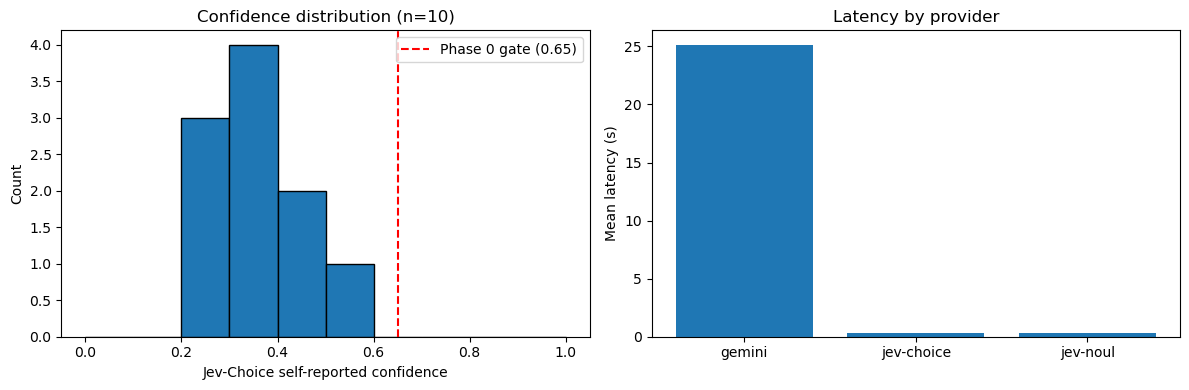

Saved chart to prototypes/outputs/20/20_summary.png


In [21]:
if not metrics_df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Confidence histogram
    confs = metrics_df["jev_choice_conf"].dropna().astype(float)
    if not confs.empty:
        axes[0].hist(confs, bins=10, range=(0, 1), edgecolor="black")
        axes[0].axvline(0.65, color="red", linestyle="--", label="Phase 0 gate (0.65)")
        axes[0].set_xlabel("Jev-Choice self-reported confidence")
        axes[0].set_ylabel("Count")
        axes[0].set_title(f"Confidence distribution (n={len(confs)})")
        axes[0].legend()

    # Latency bar
    lat_data = {
        "gemini": metrics_df["gemini_latency_s"].dropna(),
        "jev-choice": metrics_df["jev_choice_latency_s"].dropna(),
        "jev-noul": metrics_df["jev_noul_latency_s"].dropna(),
    }
    means = [d.mean() for d in lat_data.values()]
    axes[1].bar(list(lat_data.keys()), means)
    axes[1].set_ylabel("Mean latency (s)")
    axes[1].set_title("Latency by provider")

    plt.tight_layout()
    png_path = OUT_DIR / "20_summary.png"
    plt.savefig(png_path, dpi=100)
    plt.show()
    print(f"Saved chart to {png_path}")


## 9. Next steps (assuming gates pass or fail)

**If all four gates pass** → proceed to Phase 1 per `notes/ai-generated/jev-integration-plan.md`:
- Feature-flag Jev on `categorize.ts` first (additive `tagConfidence` field, no user-visible change).
- Then Phase 2: Jev ranking with Gemini fallback on `confidence < 0.5`.

**If confidence gate fails** → this is genuinely a model signal (the OpenRouter native decisions endpoint preserves calibrated confidence, so we're not measuring an artifact of the wrapper). Options: (a) enrich the outfit criteria descriptions with material/color detail to give Jev more to discriminate on; (b) split the Choice into narrower Nouls per attribute (weather-fit, occasion-fit, formality) and aggregate.

**If agreement fails** → this is either a prompt-shape mismatch (Jev is text-only; our text projection of outfits may be too thin) or a real model-quality gap. Rerun with richer `state` — include full item metadata (material, wearContext, primary_color) as structured JSON instead of terse text.

**If cost/latency fails** → check the raw usage.cost values in `prototypes/cache/20_jev_*_raw.json`. Jev's per-call cost should be ~10-30× cheaper than Gemini per the plan doc; if not, look at prompt bloat.

Raw outputs cached in `prototypes/cache/20_*.json` for post-hoc inspection.